# CellSegNet — nnUNet-style 3D Cell Segmentation

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.insert(0, "../src")

import glob
import json
import torch
import argparse
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

from pathlib import Path

In [3]:
from segmentation.train import train
from segmentation.targets import compute_all_targets

from segmentation.model import CellSegNet
from segmentation.dataset import CellSegDataset
from segmentation.losses import CellSegLoss

from segmentation.plot import plot_sample, plot_offsets, plot_preds
from segmentation.predict import load_model, predict_volume, postprocess, sigmoid
from segmentation.post_process import postprocess

In [4]:
from params import *
from utils.metrics import *
from utils.plot import *
from utils.logger import prepare_log_folder, create_logger


### Data

In [5]:
DATA_DIR = Path("../output/segs_3/")

npz_files = sorted(DATA_DIR.glob("*.npz"))
npz_files = [str(f) for f in npz_files if "targets" not in str(f)]
print(f"Found {len(npz_files)} training file(s)")

Found 10000 training file(s)


In [ ]:
data = np.load(npz_files[0], allow_pickle=False)

print("Keys and shapes:")
for k in data.files:
    try:
        v = data[k]
        print(f"  {k:12s}  shape={v.shape}  dtype={v.dtype}  range={v.min()}-{v.max()}")
    except Exception as e:
        print(f"  {k:12s}  *** corrupt: {e} ***")

img = data['img'] # (D, H, W) uint16
masks = data['masks']  # (D, H, W) uint16 instance labels
centroids = data['centroids']  # (N, 3) int32

fg_soft = (masks > 0).astype(np.float32)

D, H, W = img.shape
print(f"\nVolume    : {D} × {H} × {W}")
print(
    f"Cells     : {len(np.unique(masks)) - 1} in masks | {len(centroids)} centroids (may span multiple frames)"
)

Keys and shapes:
  img           shape=(64, 256, 256)  dtype=uint16
  masks         shape=(64, 256, 256)  dtype=uint16
  cellpose_masks  shape=(64, 256, 256)  dtype=uint16
  flows         shape=(64, 256, 256, 3)  dtype=uint8
  probas        shape=(64, 256, 256)  dtype=float32
  centroids     shape=(201, 3)  dtype=int32

Volume    : 64 × 256 × 256
Cells     : 201 in masks | 201 centroids (may span multiple frames)


In [7]:
%%time
heatmap, offsets, centroid_map = compute_all_targets(masks, sigma=3.0)

print(f"heatmap : {heatmap.shape}  range [{heatmap.min():.3f}, {heatmap.max():.3f}]")
print(
    f"offsets : {offsets.shape}  range [{offsets.min():.3f}, {offsets.max():.3f}]  (normalised to ~[-1,1])"
)
print(f"Cells derived from masks: {len(centroid_map)}")

heatmap : (64, 256, 256)  range [0.000, 1.000]
offsets : (3, 64, 256, 256)  range [-25.556, 25.444]  (normalised to ~[-1,1])
Cells derived from masks: 201
CPU times: user 782 ms, sys: 135 ms, total: 918 ms
Wall time: 917 ms


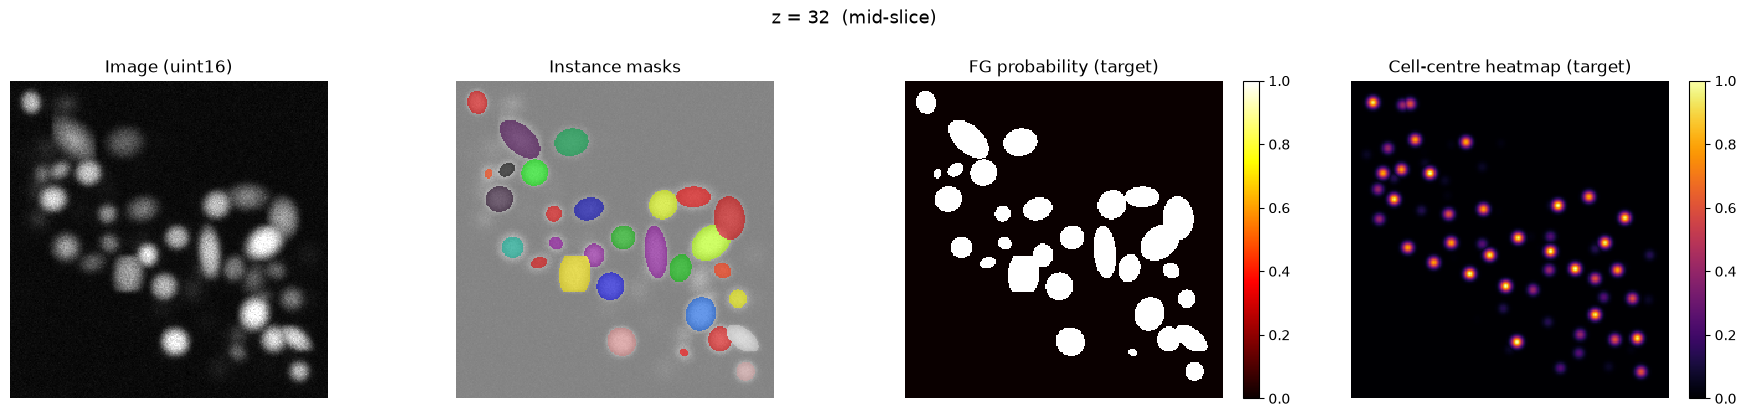

In [8]:
plot_sample(img, masks, fg_soft, heatmap, z=32)

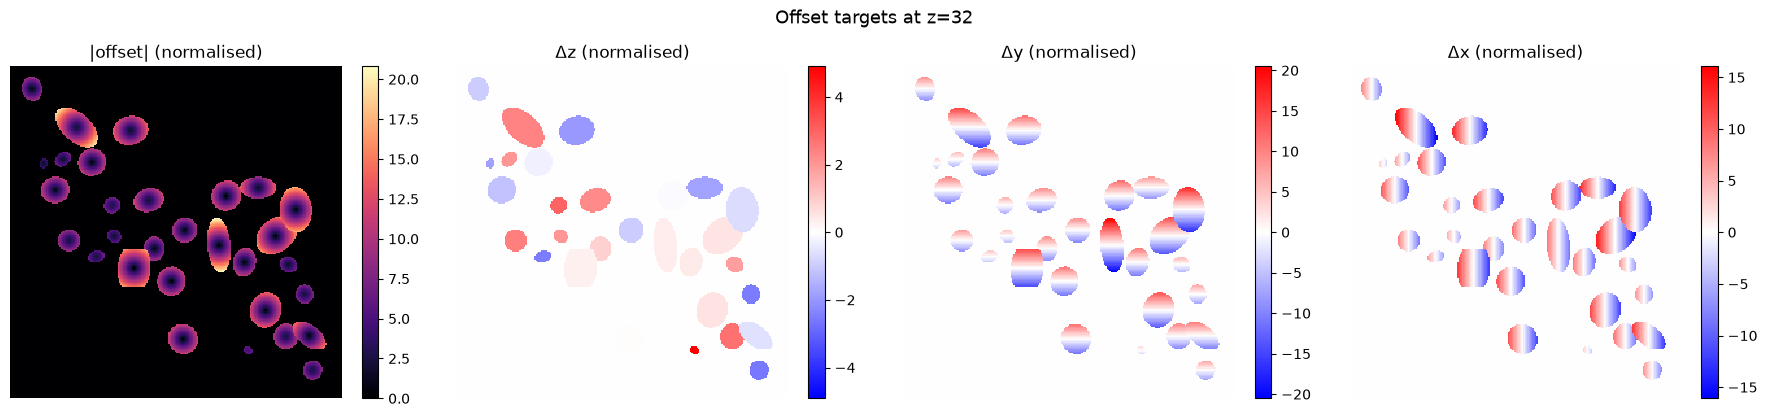

In [9]:
plot_offsets(offsets)

### Dataset

In [30]:
ds = CellSegDataset(
    str(DATA_DIR), sigma=3.0, augment=False, use_cellpose=True
)

print(f"Dataset: {len(ds)} sample(s)")

Dataset: 10000 sample(s)


In [31]:
# ds.precompute_targets()

In [40]:
sample = ds[0]
print("Sample keys/shapes:")
for k, v in sample.items():
    print(f"  {k:10s}  {tuple(v.shape)}  {v.dtype}\t range={v.min():.3f}-{v.max():.3f}")

Sample keys/shapes:
  image       (1, 64, 256, 256)  torch.float32	 range=0.000-1.000
  fg          (64, 256, 256)  torch.float32	 range=0.000-1.000
  heatmap     (64, 256, 256)  torch.float32	 range=0.000-1.000
  offsets     (3, 64, 256, 256)  torch.float32	 range=-25.556-25.444
  fg_mask     (64, 256, 256)  torch.bool	 range=0.000-1.000


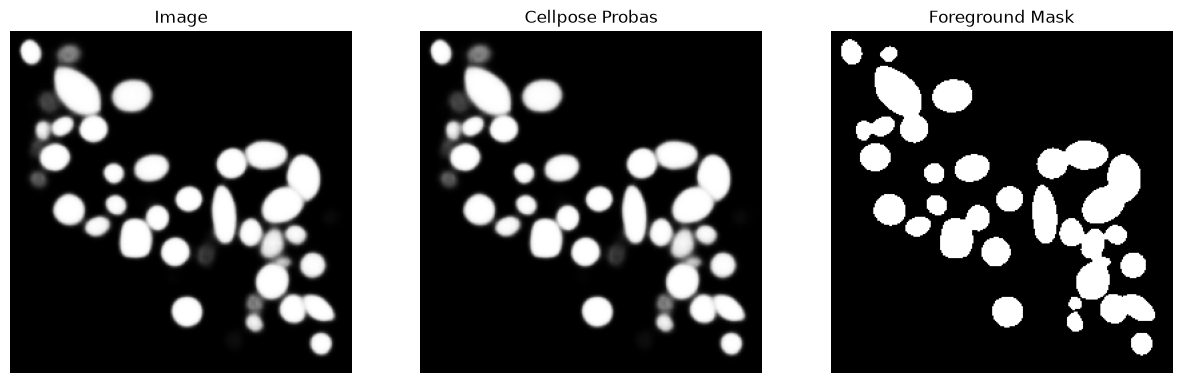

In [41]:
z = 32
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(sample["image"][0][z], cmap="gray")
plt.axis(False)
plt.title("Image")
plt.subplot(1, 3, 2)
plt.imshow(sample["image"][0][z], cmap="gray")
plt.axis(False)
plt.title("Cellpose Probas")
plt.subplot(1, 3, 3)
plt.imshow(sample["fg_mask"][z], cmap="gray")
plt.axis(False)
plt.title("Foreground Mask")
plt.show()

In [43]:
%%time
data = np.load(ds.files[0])
# sample = ds[0]

CPU times: user 470 μs, sys: 72 μs, total: 542 μs
Wall time: 556 μs


### Model

In [49]:
!uv add timm

   Updating https://www.github.com/mouseland/cellpose.git (HEAD)   
   Updating https://www.github.com/mouseland/cellpose.git (HEAD)[1A
   Updating https://www.github.com/mouseland/cellpose.git (HEAD)[1A
   Updating https://www.github.com/mouseland/cellpose.git (HEAD)[1A
   Updating https://www.github.com/mouseland/cellpose.git (HEAD)[1A
   Updating https://www.github.com/mouseland/cellpose.git (HEAD)[1A
   Updating https://www.github.com/mouseland/cellpose.git (HEAD)[1A
   Updating https://www.github.com/mouseland/cellpose.git (HEAD)[1A
   Updating https://www.github.com/mouseland/cellpose.git (HEAD)[1A
   Updating https://www.github.com/mouseland/cellpose.git (HEAD)[1A
   Updating https://www.github.com/mouseland/cellpose.git (HEAD)[1A
   Updating https://www.github.com/mouseland/cellpose.git (HEAD)[1A
   Updating https://www.github.com/mouseland/cellpose.git (HEAD)[1A
   Updating https://www.github.com/mouseland/cellpose.git (HEAD)[1A
   Updating https://www.github.com/mouseland/cel

In [48]:
from model_zoo.models_seg import define_model as define_model_seg

ModuleNotFoundError: No module named 'timm'

In [ ]:
model = define_model_seg(
    config.decoder_name,
    config.name,
    num_classes=config.num_classes,
    num_classes_aux=config.num_classes_aux,
    increase_stride=config.increase_stride,
    use_cls=config.use_cls,
    n_channels=config.n_channels,
    pretrained_weights=pretrained_weights,
    use_3d=config.use_3d,
    verbose=(config.local_rank == 0),
)

In [44]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {device}")

model = CellSegNet(features=(32, 64, 128, 256, 256), in_channels=1)
model.to(device)
print(f"Parameters: {model.count_parameters() / 1e6:.1f}M")

Device: cuda
Parameters: 20.0M


In [45]:
y = model(sample["image"].unsqueeze(0).to(device))

for k in y:
    print(k, y[k].shape)

fg_logits torch.Size([1, 1, 64, 256, 256])
heatmap_logits torch.Size([1, 1, 64, 256, 256])
offsets torch.Size([1, 3, 64, 256, 256])


### Training

In [46]:
args = argparse.Namespace(
    data_dir=str(DATA_DIR),
    use_cellpose=True,
    epochs=1,
    lr=3e-4,
    batch_size=8,
    sigma=3.0,
    features="32,64,128,256,256",
    in_channels=1,
    # patch_size=None,  # None = full 64×256×256 volume
    patch_size='64,64,64', # use this when memory is tight
    num_workers=8,  # 0 = load in main process (safe in notebooks)
    w_fg=1.0,
    w_center=1.0,
    w_heatmap=1.0,
    w_offset=1.0,
    log_every=50,
    eval_every=50,
    eval_frames=1,
    eval_sample_name="6bba_09961292",
    save_every=200,
    warmup_ratio=0,
    fp16=True,
)

In [47]:
log_folder = prepare_log_folder(log_path="../logs/")
args.output_dir = log_folder

print('-> Logging results to ', log_folder, "\n")

with open(log_folder + "args.json", "w") as f:
    json.dump(args.__dict__, f)

# create_logger(directory=log_folder, name="logs.txt")

train(args)

-> Logging results to  ../logs/2026-08-07/14/ 

Using device: cuda
Precision: FP16 mixed precision
Dataset: 10000 volumes, patch_size=(64, 64, 64)
Model parameters: 20.0M

-> Starting training...

epoch 01/01  (step 0050/1250)  lr=2.9e-04   train_loss=3.977   t=12s   det_f1=0.083   det_precision=0.044   det_recall=0.944
epoch 01/01  (step 0100/1250)  lr=2.8e-04   train_loss=1.875   t=8s   det_f1=0.084   det_precision=0.044   det_recall=0.944
epoch 01/01  (step 0150/1250)  lr=2.7e-04   train_loss=1.535   t=9s   det_f1=0.079   det_precision=0.041   det_recall=1.000
epoch 01/01  (step 0200/1250)  lr=2.5e-04   train_loss=1.376   t=9s   det_f1=0.075   det_precision=0.039   det_recall=1.000
epoch 01/01  (step 0250/1250)  lr=2.4e-04   train_loss=1.276   t=9s   det_f1=0.072   det_precision=0.037   det_recall=1.000
epoch 01/01  (step 0300/1250)  lr=2.3e-04   train_loss=1.183   t=9s   det_f1=0.070   det_precision=0.036   det_recall=1.000
epoch 01/01  (step 0350/1250)  lr=2.2e-04   train_loss=1.1

### Inference

In [ ]:
from utils.logger import Config

In [ ]:
log_folder = "../logs/2026-08-07/8/"

args = Config(json.load(open(log_folder + "args.json", "r")))

In [ ]:
checkpoints = sorted(glob.glob(log_folder + "*.pt"))
if not checkpoints:
    print("No checkpoint found — run training first.")
else:
    ckpt_path = checkpoints[-1]  # latest checkpoint
    print(f"Loading: {ckpt_path}")

Loading: ../logs/2026-08-07/8/ckpt_final.pt


In [ ]:
infer_model = load_model(str(ckpt_path), in_channels=1 + int(args.use_cellpose), device=device)

In [ ]:
sample_name = "6bba_09961292"
frame = 56
    
nodes = pd.read_csv(NODES_FOLDER + f"{sample_name}.csv")

data = np.load("../output/cellpose/" + f"{sample_name}_{frame}.npz")

gt = nodes[nodes["t"] == frame][["z", "y", "x"]].values

In [ ]:
preds = predict_volume(infer_model, data, use_cellpose=True, device=device)
print("Raw predictions:")
for k, v in preds.items():
    print(f"  {k:20s}  {v.shape}  [{v.min():.3f}, {v.max():.3f}]")

Raw predictions:
  fg_logits             (64, 256, 256)  [-22.781, 21.938]
  heatmap_logits        (64, 256, 256)  [-16.234, 2.590]
  offsets               (3, 64, 256, 256)  [-20.938, 23.266]


In [ ]:
pred_masks, pred_centroids = postprocess(
    preds,
    # fg_thresh=0.5,
    # vote_sigma=2.0,
    # nms_size=7,
    # vote_thresh_rel=0.1,
    # min_vote_voxels=10,
)

n_pred = len(pred_centroids)
print(f"Predicted cells : {n_pred}")

Predicted cells : 447


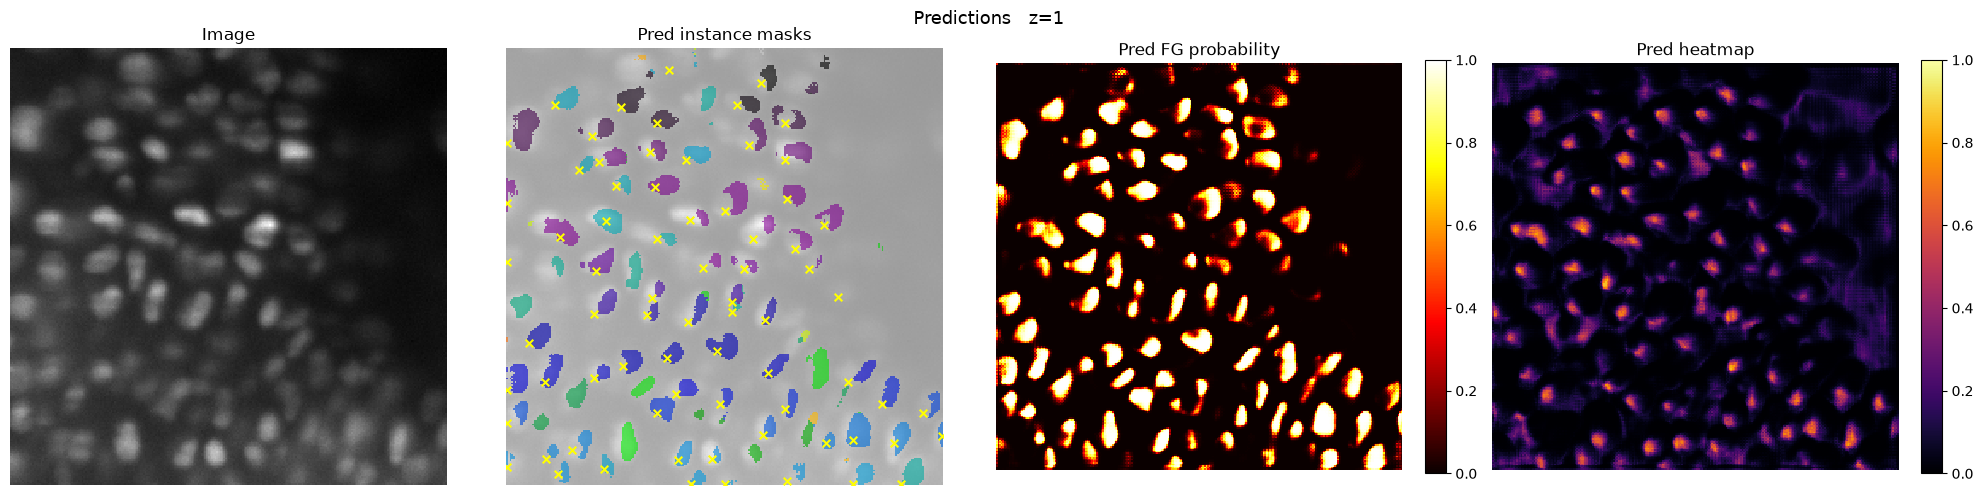

In [ ]:
z = 1

pred_fg = sigmoid(preds["fg_logits"])  # (D, H, W)  in [0,1]
pred_heatmap = sigmoid(preds["heatmap_logits"])  # (D, H, W)  in [0,1]
pred_offsets = preds["offsets"]  # (3, D, H, W) normalised

plot_preds(
    data['img'],
    pred_masks=pred_masks,
    pred_centroids=pred_centroids,
    pred_fg=pred_fg,
    pred_heatmap=pred_heatmap,
    z=z
)

In [ ]:
pairs, matched_gt, unmatched_gt = match_frame_nodes(
    pred_centroids,
    gt,
    t=frame,
    scale=SCALE,
    max_distance=7,
)

print(f'-> Matched {len(pairs)} out of {len(gt)} GT nodes')

-> Matched 18 out of 19 GT nodes


/data/kaggle-cell-tracking/.venv/lib/python3.12/site-packages/cellpose/utils.py:203: RuntimeWarning: invalid value encountered in cast
  slices = find_objects(masks.astype(int))


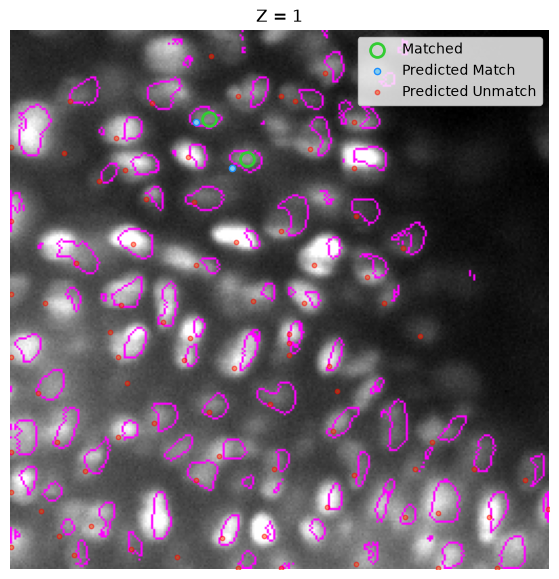

In [ ]:
mask = np.where(pred_masks > 0, pred_masks, np.nan)
tol = 3

# ids = np.unique(unmatched_gt[:, 0]) if len(unmatched_gt) > 0 else [7]
ids = np.unique(gt[:, 0])

for i in ids:    
    plt.figure(figsize=(7, 7))
    plt.title(f"Z = {i}")
    plot_contours(data['img'][i], mask[i])
    # break
    scatter_plot_center_preds(
        pred_centroids, matched_gt, unmatched_gt, frame=i, tol=tol
    )
    plt.show()

    break

#### Save predictions

In [ ]:
SAVE_DIR = MODEL_DIR / "preds"
SAVE_DIR.mkdir(parents=True, exist_ok=True)

In [ ]:
out_path = SAVE_DIR / "pred_vol_00000.npz"

np.savez_compressed(
    out_path,
    masks=pred_masks,
    centroids=pred_centroids,
    fg_prob=pred_fg,
    heatmap=pred_heatmap,
)
print(f"Saved to {out_path}")

Done 